# Stretch-move dimension factor with inactive leaves

The stretch move (Goodman & Weare 2010) proposes $x' = c + z\,(x - c)$, with $z \sim g(z) \propto 1/\sqrt{z}$ on $[1/a, a]$ and a complementary point $c$. Detailed balance needs the acceptance factor

$$\frac{p(x')}{p(x)}\; z^{\,N-1},$$

where $N$ is the number of parameters that are **actually moved**.

In Eryn, a branch is stored as an array `(ntemps, nwalkers, nleaves_max, ndim)` with a boolean `inds` saying which leaves are active. Inactive leaves are carried along by the proposal but are not part of the target. Until this fix, `GroupMove.propose` and `RedBlueMove.propose` set

```python
gibbs_ndim = nleaves_max * ndim          # (or ir.sum() for a Gibbs mask)
```

so $N$ counted the inactive slots too. Whenever some slots are inactive, which is always the case in reversible-jump runs, the factor $z^{N-1}$ is too large. Expanding steps ($z > 1$) are then accepted too often, and the posterior comes out too wide.

This affects `GroupStretchMove`, `StretchMove` and `GroupDESnookerMove`, whose factor is also $(N-1)\times\ldots$.

**The fix.** A new `Move.get_gibbs_ndim()` counts, for each walker, the active leaves that are being proposed (times the number of parameters, or times the parameters selected by a Gibbs mask). `GroupMove` and `RedBlueMove` now pass this `(ntemps, nwalkers)` array, and `adjust_factors` in `StretchMove` / `DEMove` accept it.

Below we test this on a target whose answer is known exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from eryn.ensemble import EnsembleSampler
from eryn.state import State
from eryn.prior import ProbDistContainer, uniform_dist
from eryn.moves import GroupStretchMove, StretchMove

## Test problem

One branch `"g"` with 2 parameters per leaf. Each active leaf has likelihood $\mathcal{N}(0, I_2)$, and the prior is uniform on $[-10, 10]^2$ (wide enough not to matter). The exact posterior of every active leaf is $\mathcal{N}(0, I_2)$, so the per-leaf variance must be 1, whatever `nleaves_max` is.

For `GroupStretchMove` the friends are drawn at random from a stationary pool of active leaves, refreshed every 50 iterations. The friend therefore does not depend on the walker's position, and the move is exact once the factor is right.

In [2]:
def log_like(x, groups, inds=None):
    """sum over the active leaves of each walker of -|x|^2 / 2"""
    x = x[0] if isinstance(x, list) else x
    g = groups[0] if isinstance(groups, list) else groups
    _, walker = np.unique(g, return_inverse=True)
    return np.bincount(walker, weights=-0.5 * np.sum(x**2, axis=-1))


class PoolGroupStretch(GroupStretchMove):
    """Friends drawn uniformly from a stationary pool of active leaves."""

    def setup_friends(self, branches):
        b = branches["g"]
        self.pool = b.coords[b.inds].copy()

    def find_friends(self, name, s, s_inds=None, branch_supps=None):
        j = np.random.randint(len(self.pool), size=s.shape[:-1])
        return self.pool[j]


# the behaviour before the fix: every leaf slot counted in the stretch factor
def old_gibbs_ndim(self, branch_names_run, inds_run, inds_going_for_proposal, ndims):
    return sum(
        inds_going_for_proposal[b].shape[-1] * ndims[b] if ir is None else ir.sum()
        for b, ir in zip(branch_names_run, inds_run)
    )


class OldPoolGroupStretch(PoolGroupStretch):
    get_gibbs_ndim = old_gibbs_ndim


class OldStretch(StretchMove):
    get_gibbs_ndim = old_gibbs_ndim

In [3]:
def run(move, nleaves_max, nactive, rj=False, nsteps=4000, burn=1000, seed=1):
    """Sample the test problem and return the active-leaf samples and the number of leaves."""
    np.random.seed(seed)
    ntemps, nwalkers, ndim = 1, 32, 2
    priors = {"g": ProbDistContainer({i: uniform_dist(-10, 10) for i in range(ndim)})}
    coords = {"g": np.random.randn(ntemps, nwalkers, nleaves_max, ndim)}
    inds = {"g": np.zeros((ntemps, nwalkers, nleaves_max), dtype=bool)}
    inds["g"][:, :, :nactive] = True

    ensemble = EnsembleSampler(
        nwalkers, {"g": ndim}, log_like, priors,
        tempering_kwargs=dict(ntemps=ntemps),
        nbranches=1, branch_names=["g"],
        nleaves_max={"g": nleaves_max}, nleaves_min={"g": 1 if rj else nactive},
        provide_groups=True, vectorize=True,
        moves=move, rj_moves=rj,
    )
    ensemble.random_state = np.random.RandomState(seed).get_state()
    ensemble.run_mcmc(State(coords, inds=inds), nsteps, burn=burn, progress=False)

    chain = ensemble.backend.get_chain()["g"][:, 0]
    active = ensemble.backend.get_inds()["g"][:, 0]
    return chain[active], active.sum(axis=-1)

## `GroupStretchMove`: before and after

3 active leaves, with 3, 10 or 20 leaf slots, plus a reversible-jump run where the number of leaves is free (1 to 10). For RJ, every extra leaf multiplies the evidence by $2\pi/400$, so $\langle k \rangle \simeq 1.016$.

In [4]:
cases = [(3, 3, False), (10, 3, False), (20, 3, False), (10, 3, True)]
results = {}
print(f"{'nleaves_max':>11} {'active':>6} {'rj':>5} | {'var before':>16} | {'var after':>16} | <k> after")
for L, k, rj in cases:
    before, _ = run(OldPoolGroupStretch(nfriends=1, n_iter_update=50), L, k, rj)
    after, kk = run(PoolGroupStretch(nfriends=1, n_iter_update=50), L, k, rj)
    results[(L, k, rj)] = before, after
    print(f"{L:>11} {k:>6} {rj!s:>5} | {np.array2string(before.var(0), precision=3):>16} | "
          f"{np.array2string(after.var(0), precision=3):>16} | {kk.mean():.3f}")

nleaves_max active    rj |       var before |        var after | <k> after


          3      3 False |    [1.001 1.017] |    [1.001 1.017] | 3.000


         10      3 False |    [3.442 3.347] |    [1.01  1.003] | 3.000


         20      3 False |    [6.907 6.89 ] |    [1.012 1.001] | 3.000


         10      3  True |    [8.655 8.716] |    [0.99  1.039] | 1.016


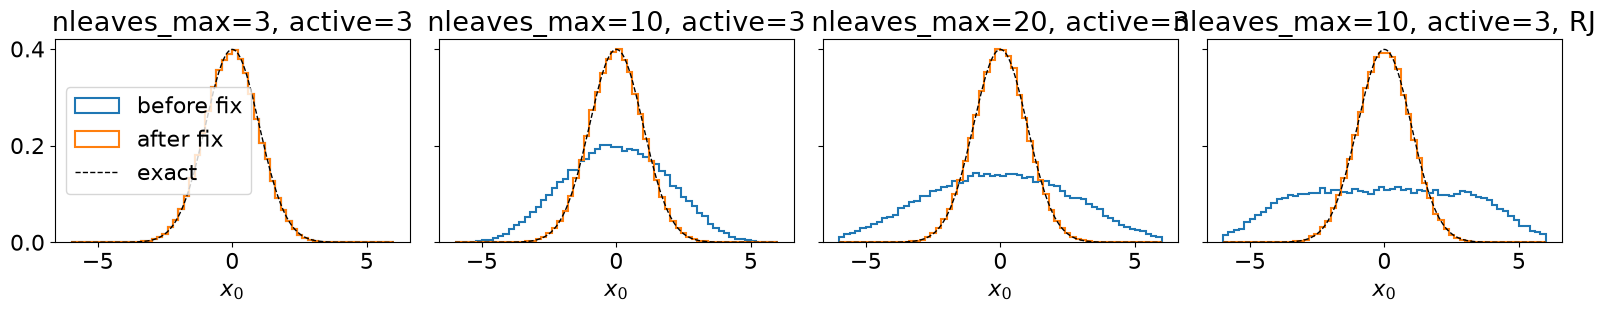

In [5]:
xx = np.linspace(-6, 6, 300)
fig, axes = plt.subplots(1, len(cases), figsize=(16, 3.4), sharey=True)
for ax, (L, k, rj) in zip(axes, cases):
    before, after = results[(L, k, rj)]
    bins = np.linspace(-6, 6, 61)
    ax.hist(before[:, 0], bins=bins, density=True, histtype="step", lw=1.5, label="before fix")
    ax.hist(after[:, 0], bins=bins, density=True, histtype="step", lw=1.5, label="after fix")
    ax.plot(xx, np.exp(-xx**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="exact")
    ax.set_title(f"nleaves_max={L}, active={k}" + (", RJ" if rj else ""))
    ax.set_xlabel("$x_0$")
axes[0].legend()
plt.tight_layout()

With all slots active (first panel) both versions agree, because nothing is miscounted. As soon as slots are inactive, the old factor inflates the variance, and the more empty slots there are the worse it gets. The fixed version recovers $\mathcal{N}(0, 1)$ in every case, including RJ.

## `StretchMove` has the same problem

The red-blue `StretchMove` used the same expression. (It needs `live_dangerously=True` here, because its walker check also counts the inactive slots.)

In [6]:
print(f"{'nleaves_max':>11} {'active':>6} | {'var before':>16} | {'var after':>16}")
for L, k in [(3, 3), (10, 3)]:
    before, _ = run(OldStretch(live_dangerously=True), L, k)
    after, _ = run(StretchMove(live_dangerously=True), L, k)
    print(f"{L:>11} {k:>6} | {np.array2string(before.var(0), precision=3):>16} | "
          f"{np.array2string(after.var(0), precision=3):>16}")

nleaves_max active |       var before |        var after


          3      3 |    [0.995 1.006] |    [0.995 1.006]


         10      3 |    [3.349 3.312] |    [0.998 1.001]


## Gibbs masks

With `gibbs_sampling_setup=[("g", mask)]`, the old code used `mask.sum()`, which counts the masked slots whether they are active or not. The fix counts only the masked slots that are active. Here the mask selects leaves 0 and 1 (active) and leaf 5 (inactive).

In [7]:
mask = np.zeros((10, 2), dtype=bool)
mask[[0, 1, 5]] = True


def leaf_variances(move_cls):
    import eryn.ensemble
    chains = {}
    orig = eryn.ensemble.EnsembleSampler.run_mcmc

    def keep_chain(self, *args, **kwargs):
        out = orig(self, *args, **kwargs)
        chains["c"] = self.backend.get_chain()["g"][:, 0]
        return out

    eryn.ensemble.EnsembleSampler.run_mcmc = keep_chain
    try:
        run(move_cls(nfriends=1, n_iter_update=50, gibbs_sampling_setup=[("g", mask)]), 10, 3)
    finally:
        eryn.ensemble.EnsembleSampler.run_mcmc = orig
    c = chains["c"]
    return c[:, :, 0].var(axis=(0, 1)), c[:, :, 1].var(axis=(0, 1))


for name, cls in [("before", OldPoolGroupStretch), ("after", PoolGroupStretch)]:
    v0, v1 = leaf_variances(cls)
    print(f"{name:>6}: leaf 0 var {np.round(v0, 3)}, leaf 1 var {np.round(v1, 3)}   (exact 1)")

before: leaf 0 var [1.495 1.452], leaf 1 var [1.458 1.466]   (exact 1)


 after: leaf 0 var [1.045 0.995], leaf 1 var [0.997 0.976]   (exact 1)


## Summary of the code changes (`src/eryn/moves/`)

| File | Change |
|---|---|
| `move.py` | new `Move.get_gibbs_ndim()`: moved dimension per walker, counting only active leaves and Gibbs-selected parameters |
| `group.py` | `GroupMove.propose` uses it (covers `GroupStretchMove` and `GroupDESnookerMove`); `nfriends=None` no longer crashes on `int(None)` |
| `red_blue.py` | `RedBlueMove.propose` uses it for the walkers of each split (covers `StretchMove`) |
| `stretch.py`, `de.py` | `adjust_factors` accepts a per-walker array of dimensions |

Runs that used these moves with inactive leaf slots, which includes every RJ run that used `GroupStretchMove`, were sampling a posterior wider than the true one.